In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [115]:
# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object


In [116]:
# Step 3: Separate features and target

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget:")
print("median_house_value")

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical features:
['ocean_proximity']

Target:
median_house_value


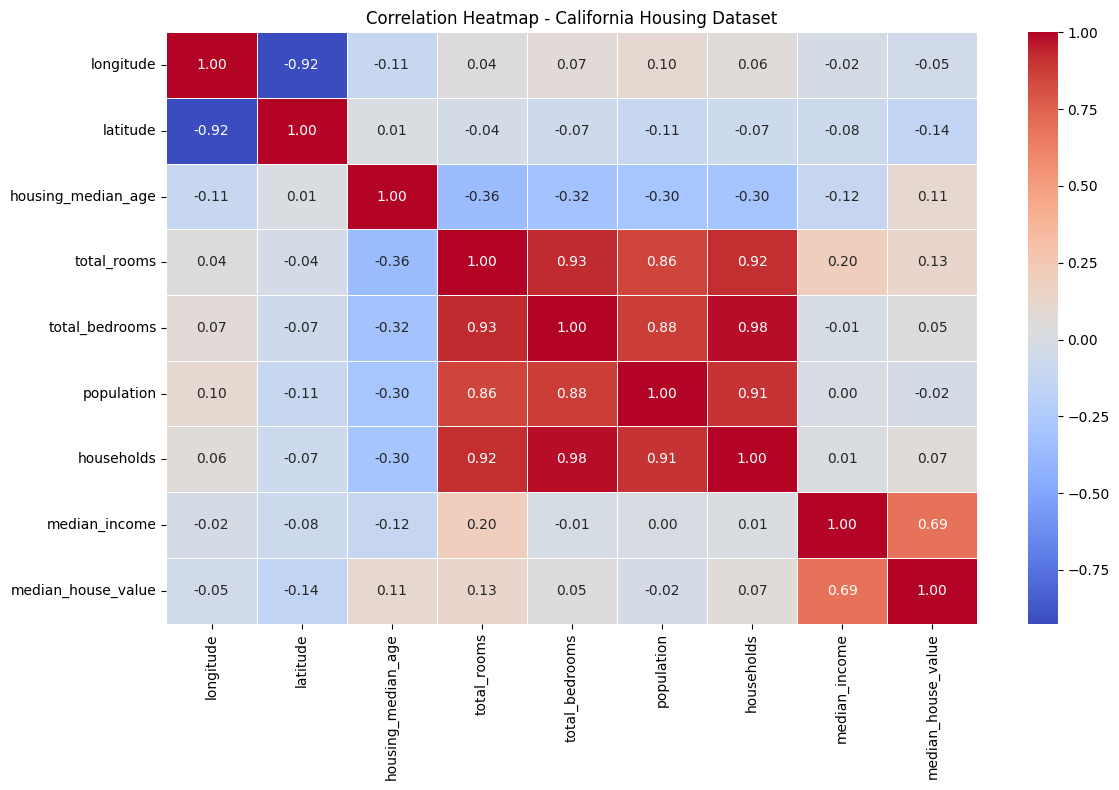

In [117]:
# Step 4: Correlation heatmap

plt.figure(figsize=(12, 8))

correlation_matrix = df[numeric_features + ["median_house_value"]].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - California Housing Dataset")
plt.tight_layout()
plt.show()

In [118]:
# Step 5: Feature Engineering - Interaction Features

df_engineered = df.copy()

# Create useful interaction / ratio features
df_engineered["rooms_per_household"] = (
    df_engineered["total_rooms"] / df_engineered["households"]
)

df_engineered["bedrooms_per_room"] = (
    df_engineered["total_bedrooms"] / df_engineered["total_rooms"]
)

df_engineered["population_per_household"] = (
    df_engineered["population"] / df_engineered["households"]
)

# Replace infinite values, if any
df_engineered.replace([np.inf, -np.inf], np.nan, inplace=True)

print("New features created:")
print([
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household"
])

print("\nNew dataset shape:", df_engineered.shape)

df_engineered.head()

New features created:
['rooms_per_household', 'bedrooms_per_room', 'population_per_household']

New dataset shape: (20640, 13)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,6.281853,0.172096,2.181467


In [119]:
# Step 6: Train-Test Split and Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate features and target
X = df_engineered.drop("median_house_value", axis=1)
y = df_engineered["median_house_value"]

# Identify columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

Training samples: 16512
Testing samples: 4128
Numerical features: 11
Categorical features: ['ocean_proximity']


In [120]:
# Step 7: OLS Linear Regression

ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Train OLS model
ols_model.fit(X_train, y_train)

# Predictions
y_pred_ols = ols_model.predict(X_test)

# Evaluation metrics
rmse_ols = np.sqrt(mean_squared_error(y_test, y_pred_ols))
mae_ols = mean_absolute_error(y_test, y_pred_ols)
r2_ols = r2_score(y_test, y_pred_ols)

print("OLS (Linear Regression) Results")
print("--------------------------------")
print(f"RMSE: {rmse_ols:.2f}")
print(f"MAE : {mae_ols:.2f}")
print(f"R²  : {r2_ols:.4f}")

OLS (Linear Regression) Results
--------------------------------
RMSE: 69127.04
MAE : 49645.49
R²  : 0.6353


In [121]:
# Step 8: Ridge Regression with GridSearchCV

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

# Alpha values to test
ridge_params = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100]
}

# Grid Search
ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Train Ridge with GridSearchCV
ridge_grid.fit(X_train, y_train)

# Best model
best_ridge = ridge_grid.best_estimator_

# Predictions
y_pred_ridge = best_ridge.predict(X_test)

# Evaluation
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Results")
print("------------------------")
print("Best Alpha:", ridge_grid.best_params_["regressor__alpha"])
print(f"RMSE: {rmse_ridge:.2f}")
print(f"MAE : {mae_ridge:.2f}")
print(f"R²  : {r2_ridge:.4f}")

Ridge Regression Results
------------------------
Best Alpha: 1
RMSE: 69134.97
MAE : 49652.14
R²  : 0.6353


In [122]:
# Step 9: Lasso Regression with GridSearchCV

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=10000))
])

# Alpha values to test
lasso_params = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100]
}

# Grid Search
lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Train Lasso with GridSearchCV
lasso_grid.fit(X_train, y_train)

# Best model
best_lasso = lasso_grid.best_estimator_

# Predictions
y_pred_lasso = best_lasso.predict(X_test)

# Evaluation
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso Regression Results")
print("------------------------")
print("Best Alpha:", lasso_grid.best_params_["regressor__alpha"])
print(f"RMSE: {rmse_lasso:.2f}")
print(f"MAE : {mae_lasso:.2f}")
print(f"R²  : {r2_lasso:.4f}")

Lasso Regression Results
------------------------
Best Alpha: 1
RMSE: 69128.09
MAE : 49646.43
R²  : 0.6353


In [123]:
# Step 10: Compare OLS, Ridge and Lasso

results = pd.DataFrame({
    "Model": [
        "OLS (Linear Regression)",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "RMSE": [
        rmse_ols,
        rmse_ridge,
        rmse_lasso
    ],
    "MAE": [
        mae_ols,
        mae_ridge,
        mae_lasso
    ],
    "R²": [
        r2_ols,
        r2_ridge,
        r2_lasso
    ]
})

results = results.round(4)

print(results)

                     Model        RMSE         MAE      R²
0  OLS (Linear Regression)  69127.0383  49645.4924  0.6353
1         Ridge Regression  69134.9653  49652.1429  0.6353
2         Lasso Regression  69128.0912  49646.4289  0.6353


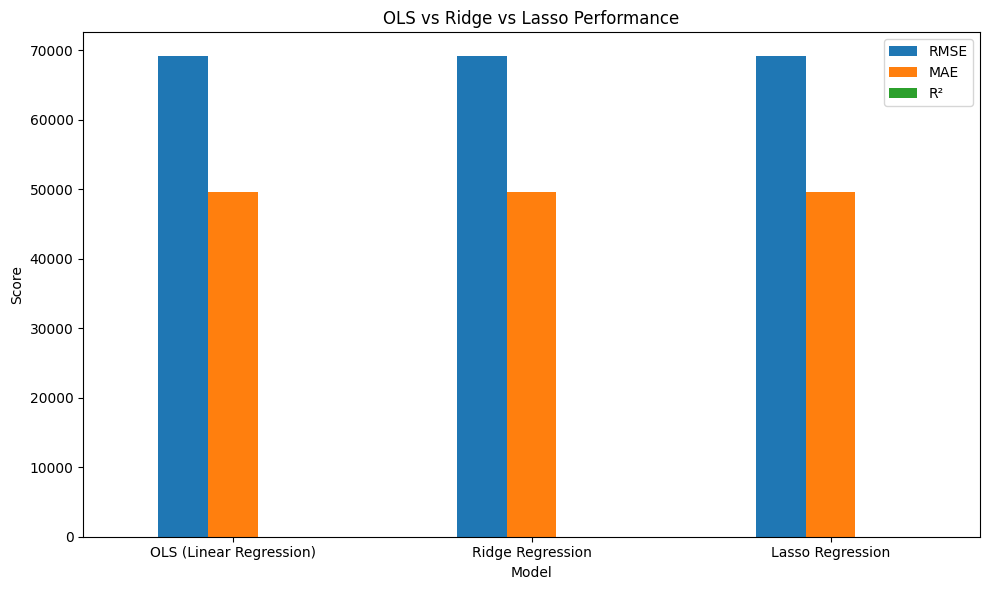

In [124]:
# Performance comparison chart

results_plot = results.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("OLS vs Ridge vs Lasso Performance")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

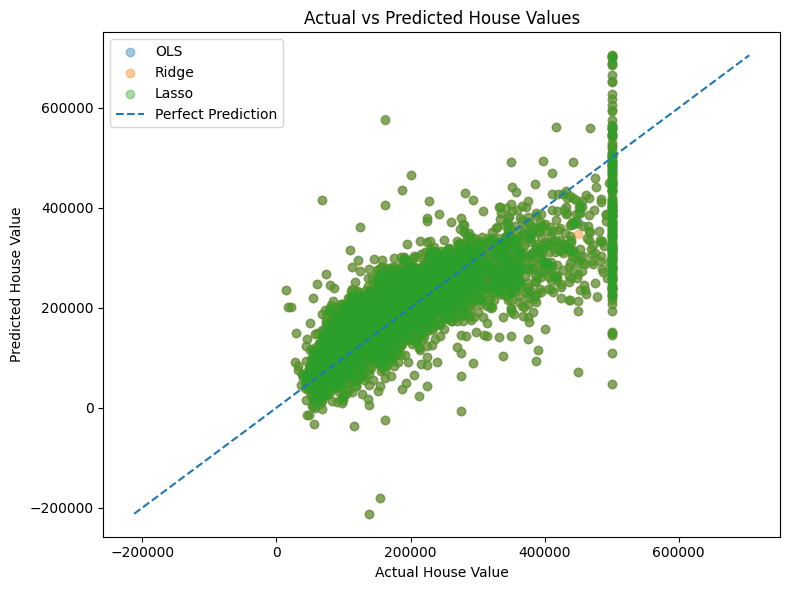

In [125]:
# Step 11: Actual vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_ols,
    alpha=0.4,
    label="OLS"
)

plt.scatter(
    y_test,
    y_pred_ridge,
    alpha=0.4,
    label="Ridge"
)

plt.scatter(
    y_test,
    y_pred_lasso,
    alpha=0.4,
    label="Lasso"
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_ols.min())
max_value = max(y_test.max(), y_pred_ols.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")
plt.legend()
plt.tight_layout()
plt.show()

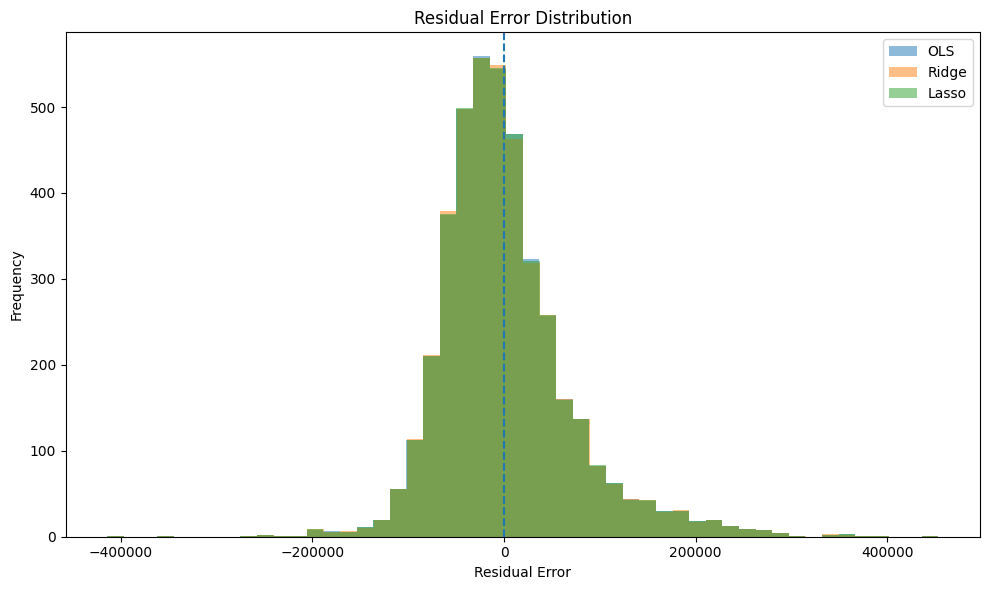

In [126]:
# Step 12: Residual Error Analysis

residuals_ols = y_test - y_pred_ols
residuals_ridge = y_test - y_pred_ridge
residuals_lasso = y_test - y_pred_lasso

plt.figure(figsize=(10, 6))

plt.hist(residuals_ols, bins=50, alpha=0.5, label="OLS")
plt.hist(residuals_ridge, bins=50, alpha=0.5, label="Ridge")
plt.hist(residuals_lasso, bins=50, alpha=0.5, label="Lasso")

plt.axvline(0, linestyle="--")

plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.title("Residual Error Distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [127]:
# Step 13: Final Results

print("FINAL MODEL COMPARISON")
print("=" * 50)

print(results.to_string(index=False))

FINAL MODEL COMPARISON
                  Model       RMSE        MAE     R²
OLS (Linear Regression) 69127.0383 49645.4924 0.6353
       Ridge Regression 69134.9653 49652.1429 0.6353
       Lasso Regression 69128.0912 49646.4289 0.6353


In [128]:
# Best model based on RMSE

best_model = results.loc[results["RMSE"].idxmin(), "Model"]

print("\nBest Model based on RMSE:", best_model)


Best Model based on RMSE: OLS (Linear Regression)


In [ ]:
## Conclusion

The California Housing dataset was used to build an end-to-end house price prediction pipeline.

The dataset was preprocessed by handling missing values, encoding the categorical feature, standardizing numerical features, and creating new interaction features.

Three regression models were trained and compared:
- OLS (Linear Regression)
- Ridge Regression
- Lasso Regression

The models were evaluated using RMSE, MAE, and R². OLS achieved the lowest RMSE and MAE among the three models, while all models produced a similar R² score of approximately 0.6353.

Actual vs predicted plots and residual error analysis were also performed to understand model performance and prediction errors.

Overall, this project demonstrates a complete regression workflow using Python and Scikit-Learn, including preprocessing, feature engineering, model tuning, evaluation, and visualization.